# 02 Data Cleaning

In diesem Notebook werden die in `01_data_generation.ipynb` erzeugten Kredit- und Score-Daten bereinigt und für die weitere Analyse vorbereitet.

## Ziele
- Datensatz laden
- Datenstruktur und Spalten prüfen
- fehlende Werte analysieren
- Datentypen korrigieren
- Plausibilitätsprüfungen durchführen
- logische Inkonsistenzen erkennen
- neue Analysevariablen erzeugen
- bereinigte Daten speichern

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
sns.set_style("whitegrid")

## 1. Datei laden

Dieses Notebook ist so aufgebaut, dass es sowohl mit einer Testdatei als auch mit einer später korrigierten Datei funktioniert.

In [34]:
import os
import pandas as pd

possible_paths = [
    "test_credit_upload_file.csv",
    "credit_score_dataset.csv",
    "schufa_credit_dataset.csv",
    "data/raw/test_credit_upload_file.csv",
    "data/raw/credit_score_dataset.csv",
    "data/raw/schufa_credit_dataset.csv"
]

file_path = None

# 1. Prüfen, ob eine bekannte Datei schon existiert
for path in possible_paths:
    if os.path.exists(path):
        file_path = path
        break

# 2. Falls nichts gefunden wurde: Upload erlauben
if file_path is None:
    try:
        from google.colab import files

        print("Keine lokale CSV gefunden. Bitte jetzt deine Datei hochladen.")
        uploaded = files.upload()

        if len(uploaded) == 0:
            raise FileNotFoundError("Es wurde keine Datei hochgeladen.")

        uploaded_filename = list(uploaded.keys())[0]
        file_path = uploaded_filename
        print(f"Datei erfolgreich hochgeladen: {file_path}")

    except ImportError:
        raise FileNotFoundError(
            "Keine passende Eingabedatei gefunden. "
            "Wenn du nicht in Google Colab arbeitest, lege die CSV bitte manuell "
            "ins Projektverzeichnis oder in data/raw/ ab."
        )

# 3. Datei laden
df = pd.read_csv(file_path)

print("Datensatz erfolgreich geladen.")
print("Verwendete Datei:", file_path)
print("Shape:", df.shape)

Keine lokale CSV gefunden. Bitte jetzt deine Datei hochladen.


Saving synthetic_schufa_dataset.csv to synthetic_schufa_dataset.csv
Datei erfolgreich hochgeladen: synthetic_schufa_dataset.csv
Datensatz erfolgreich geladen.
Verwendete Datei: synthetic_schufa_dataset.csv
Shape: (10000, 21)


In [35]:
df.head()

,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,1,9.2,0,0,4301.25,5.03,100.0,100.0,1,1,0
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,0,9.6,0,0,3233.97,2.04,100.0,100.0,0,1,0
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,2,10.8,0,0,-409.95,-0.16,93.8,100.0,1,1,1
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,2,5.6,0,0,-1898.47,-1.78,98.6,100.0,1,1,0
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,1,8.6,0,0,1761.98,1.31,96.7,99.4,1,1,0


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         10000 non-null  int64  
 1   net_income                  10000 non-null  float64
 2   employment_status           10000 non-null  object 
 3   marital_status              10000 non-null  object 
 4   dependents                  10000 non-null  int64  
 5   monthly_expenses            10000 non-null  float64
 6   existing_loans              10000 non-null  int64  
 7   credit_amount               10000 non-null  float64
 8   debt_to_income              10000 non-null  float64
 9   late_payments               10000 non-null  int64  
 10  hard_inquiries              10000 non-null  int64  
 11  credit_history_years        10000 non-null  float64
 12  negative_entry              10000 non-null  int64  
 13  collection_cases            1000

In [37]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,10000.0,NaN,NaN,NaN,43.5394,14.911636,18.0,31.0,43.0,56.0,69.0
net_income,10000.0,NaN,NaN,NaN,2923.520144,1214.299368,800.0,2043.9125,2874.86,3745.8675,7034.87
employment_status,10000,4,angestellt,5761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,10000,3,ledig,4523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,10000.0,NaN,NaN,NaN,1.0734,1.219738,0.0,0.0,1.0,2.0,4.0
monthly_expenses,10000.0,NaN,NaN,NaN,1829.76599,856.490901,500.0,1199.6275,1714.225,2355.675,5653.03
existing_loans,10000.0,NaN,NaN,NaN,1.2014,1.095335,0.0,0.0,1.0,2.0,6.0
credit_amount,10000.0,NaN,NaN,NaN,11950.005553,8191.212565,500.0,5380.7375,10250.615,16868.635,50000.0
debt_to_income,10000.0,NaN,NaN,NaN,0.353241,0.180269,0.04,0.2,0.35,0.51,0.67
late_payments,10000.0,NaN,NaN,NaN,1.0232,1.014083,0.0,0.0,1.0,2.0,6.0


## 2. Spaltennamen bereinigen und standardisieren

In [38]:
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(" ", "_", regex=False)
              .str.replace("-", "_", regex=False)
)

print(df.columns.tolist())

['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']


## 3. Erwartete Struktur prüfen

Hier prüfen wir, ob die Spalten aus `01_data_generation.ipynb` vorhanden sind.

In [39]:
expected_columns = [
    "age",
    "net_income",
    "employment_status",
    "marital_status",
    "dependents",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score",
    "credit_approved_old_system",
    "credit_approved_new_system",
    "default"
]

missing_cols = [col for col in expected_columns if col not in df.columns]
extra_cols = [col for col in df.columns if col not in expected_columns]

print("Fehlende erwartete Spalten:", missing_cols)
print("Zusätzliche Spalten:", extra_cols)

Fehlende erwartete Spalten: []
Zusätzliche Spalten: []


## 4. Fehlende Werte analysieren

In [40]:
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values(by="missing_count", ascending=False)

missing_df

,missing_count,missing_percent
age,0,0.0
net_income,0,0.0
employment_status,0,0.0
marital_status,0,0.0
dependents,0,0.0
monthly_expenses,0,0.0
existing_loans,0,0.0
credit_amount,0,0.0
debt_to_income,0,0.0
late_payments,0,0.0


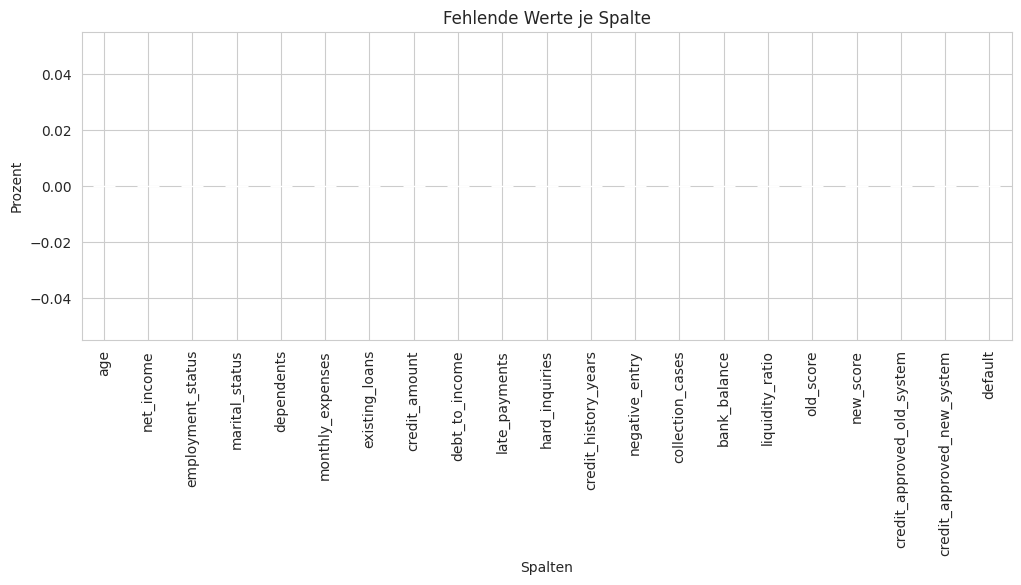

In [41]:
plt.figure(figsize=(12, 4))
missing_df["missing_percent"].plot(kind="bar")
plt.title("Fehlende Werte je Spalte")
plt.ylabel("Prozent")
plt.xlabel("Spalten")
plt.show()

In [42]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerische Spalten:", numeric_cols)
print("Kategorische Spalten:", categorical_cols)

Numerische Spalten: ['age', 'net_income', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']
Kategorische Spalten: ['employment_status', 'marital_status']


In [43]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna("unknown")

print("Verbleibende fehlende Werte:", df.isna().sum().sum())

Verbleibende fehlende Werte: 0


## 5. Duplikate prüfen

In [44]:
duplicates = df.duplicated().sum()
print("Anzahl vollständiger Duplikate:", duplicates)

Anzahl vollständiger Duplikate: 0


In [45]:
df = df.drop_duplicates()
print("Shape nach Entfernen von Duplikaten:", df.shape)

Shape nach Entfernen von Duplikaten: (10000, 21)


## 6. Datentypen bereinigen

In [46]:
numeric_columns_expected = [
    "age",
    "net_income",
    "dependents",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "negative_entry",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score",
    "credit_approved_old_system",
    "credit_approved_new_system",
    "default"
]

for col in numeric_columns_expected:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

In [47]:
binary_cols = [
    "negative_entry",
    "credit_approved_old_system",
    "credit_approved_new_system",
    "default"
]

for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].astype("Int64")

In [48]:
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.lower()

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         10000 non-null  int64  
 1   net_income                  10000 non-null  float64
 2   employment_status           10000 non-null  object 
 3   marital_status              10000 non-null  object 
 4   dependents                  10000 non-null  int64  
 5   monthly_expenses            10000 non-null  float64
 6   existing_loans              10000 non-null  int64  
 7   credit_amount               10000 non-null  float64
 8   debt_to_income              10000 non-null  float64
 9   late_payments               10000 non-null  int64  
 10  hard_inquiries              10000 non-null  int64  
 11  credit_history_years        10000 non-null  float64
 12  negative_entry              10000 non-null  Int64  
 13  collection_cases            1000

## 7. Kategorische Variablen prüfen

In [50]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- employment_status ---
employment_status
angestellt       5761
selbstständig    1770
teilzeit         1678
arbeitslos        791
Name: count, dtype: int64

--- marital_status ---
marital_status
ledig          4523
verheiratet    3996
geschieden     1481
Name: count, dtype: int64


## 8. Plausibilitätsprüfungen

Hier prüfen wir, ob die wichtigsten Wertebereiche sinnvoll sind.

In [52]:
checks = {}

if "age" in df.columns:
    checks["age_outside_18_70"] = ((df["age"] < 18) | (df["age"] > 70)).sum()

if "net_income" in df.columns:
    checks["negative_net_income"] = (df["net_income"] < 0).sum()

if "monthly_expenses" in df.columns:
    checks["negative_monthly_expenses"] = (df["monthly_expenses"] < 0).sum()

if "credit_amount" in df.columns:
    checks["negative_credit_amount"] = (df["credit_amount"] < 0).sum()

if "existing_loans" in df.columns:
    checks["negative_existing_loans"] = (df["existing_loans"] < 0).sum()

if "late_payments" in df.columns:
    checks["negative_late_payments"] = (df["late_payments"] < 0).sum()

if "hard_inquiries" in df.columns:
    checks["negative_hard_inquiries"] = (df["hard_inquiries"] < 0).sum()

if "collection_cases" in df.columns:
    checks["negative_collection_cases"] = (df["collection_cases"] < 0).sum()

pd.DataFrame.from_dict(checks, orient="index", columns=["count"])

,count
age_outside_18_70,0
negative_net_income,0
negative_monthly_expenses,0
negative_credit_amount,0
negative_existing_loans,0
negative_late_payments,0
negative_hard_inquiries,0
negative_collection_cases,0


In [53]:
if "old_score" in df.columns:
    print("old_score außerhalb 0-100:", ((df["old_score"] < 0) | (df["old_score"] > 100)).sum())

if "new_score" in df.columns:
    print("new_score außerhalb 0-100:", ((df["new_score"] < 0) | (df["new_score"] > 100)).sum())

old_score außerhalb 0-100: 0
new_score außerhalb 0-100: 0


## 9. Logische Inkonsistenzen prüfen

In der Datenpipeline kann es vorkommen, dass `net_income` später angepasst wurde, `debt_to_income` aber noch auf dem alten Wert basiert.

Deshalb berechnen wir `debt_to_income` neu.

In [54]:
if {"credit_amount", "net_income"}.issubset(df.columns):
    df["debt_to_income_recalc"] = np.round(
        df["credit_amount"] / (df["net_income"] * 12),
        4
    )

In [55]:
if {"debt_to_income", "debt_to_income_recalc"}.issubset(df.columns):
    df["debt_to_income_diff"] = np.round(
        df["debt_to_income_recalc"] - df["debt_to_income"],
        4
    )

    df["dti_inconsistency_flag"] = np.where(
        df["debt_to_income_diff"].abs() > 0.01,
        1,
        0
    )

    print("Inkonsistente DTI-Werte:", df["dti_inconsistency_flag"].sum())
    print("Anteil inkonsistenter Zeilen in %:", round(df["dti_inconsistency_flag"].mean() * 100, 2))

Inkonsistente DTI-Werte: 484
Anteil inkonsistenter Zeilen in %: 4.84


In [57]:
if "debt_to_income_recalc" in df.columns:
    df["debt_to_income_clean"] = df["debt_to_income_recalc"]

## 10. Kreditentscheidungen auf bereinigter Grundlage neu berechnen

In [58]:
if {"old_score", "debt_to_income_clean"}.issubset(df.columns):
    df["credit_approved_old_system_clean"] = np.where(
        (df["old_score"] >= 60) & (df["debt_to_income_clean"] < 0.45),
        1,
        0
    )

if {"new_score", "debt_to_income_clean"}.issubset(df.columns):
    df["credit_approved_new_system_clean"] = np.where(
        (df["new_score"] >= 60) & (df["debt_to_income_clean"] < 0.50),
        1,
        0
    )

In [59]:
if {"credit_approved_old_system", "credit_approved_old_system_clean"}.issubset(df.columns):
    old_changes = (df["credit_approved_old_system"] != df["credit_approved_old_system_clean"]).sum()
    print("Abweichungen altes System:", old_changes)

if {"credit_approved_new_system", "credit_approved_new_system_clean"}.issubset(df.columns):
    new_changes = (df["credit_approved_new_system"] != df["credit_approved_new_system_clean"]).sum()
    print("Abweichungen neues System:", new_changes)

Abweichungen altes System: 153
Abweichungen neues System: 182


## 11. Neue Analysevariablen erzeugen

In [60]:
if {"monthly_expenses", "net_income"}.issubset(df.columns):
    df["expense_to_income_ratio"] = np.round(
        df["monthly_expenses"] / df["net_income"],
        4
    )

if {"bank_balance", "net_income"}.issubset(df.columns):
    df["balance_to_income_ratio"] = np.round(
        df["bank_balance"] / df["net_income"],
        4
    )

In [61]:
if {"net_income", "negative_entry"}.issubset(df.columns):
    df["high_income_negative_entry"] = np.where(
        (df["net_income"] >= 4000) & (df["negative_entry"] == 1),
        1,
        0
    )

if {"bank_balance", "negative_entry"}.issubset(df.columns):
    df["high_liquidity_negative_entry"] = np.where(
        (df["bank_balance"] >= 4000) & (df["negative_entry"] == 1),
        1,
        0
    )

if {"net_income", "bank_balance", "negative_entry"}.issubset(df.columns):
    df["high_income_high_liquidity_negative_entry"] = np.where(
        (df["net_income"] >= 4000) &
        (df["bank_balance"] >= 4000) &
        (df["negative_entry"] == 1),
        1,
        0
    )

In [62]:
if "net_income" in df.columns:
    df["income_group"] = pd.cut(
        df["net_income"],
        bins=[0, 1500, 2500, 4000, 7000, np.inf],
        labels=["very_low", "low", "middle", "upper_middle", "high"]
    )

if "age" in df.columns:
    df["age_group"] = pd.cut(
        df["age"],
        bins=[18, 25, 35, 50, 65, 70],
        labels=["18-25", "26-35", "36-50", "51-65", "66-70"],
        include_lowest=True
    )

## 12. Ausreißer sichtbar machen

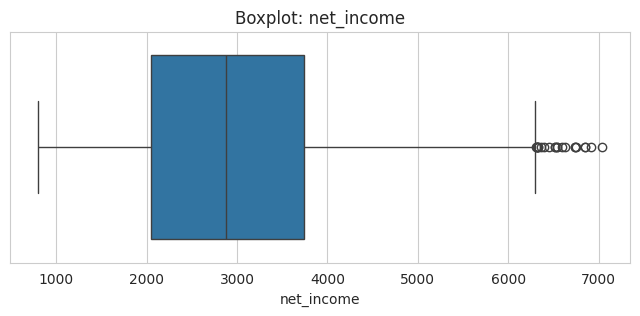

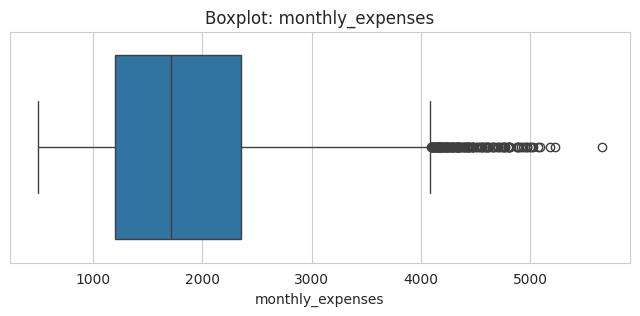

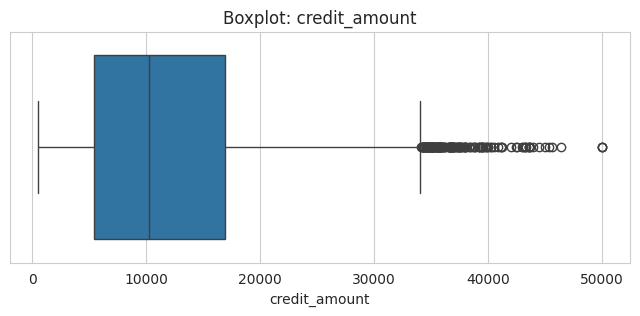

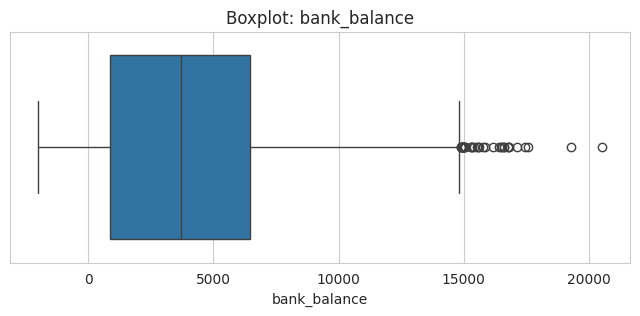

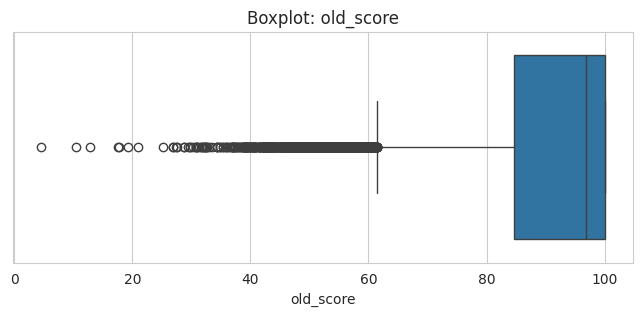

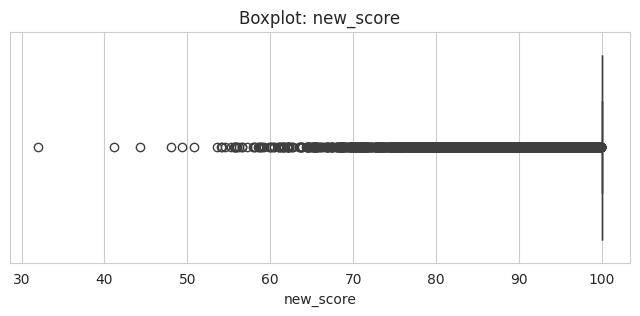

In [63]:
plot_cols = [
    "net_income",
    "monthly_expenses",
    "credit_amount",
    "bank_balance",
    "old_score",
    "new_score"
]

plot_cols = [col for col in plot_cols if col in df.columns]

for col in plot_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")
    plt.show()

## 13. Finale Qualitätsprüfung

In [64]:
print("Finale Shape:", df.shape)
print("Fehlende Werte gesamt:", df.isna().sum().sum())
print("Duplikate:", df.duplicated().sum())

Finale Shape: (10000, 34)
Fehlende Werte gesamt: 0
Duplikate: 0


In [65]:
df.head()

,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default,debt_to_income_recalc,debt_to_income_diff,dti_inconsistency_flag,debt_to_income_clean,credit_approved_old_system_clean,credit_approved_new_system_clean,expense_to_income_ratio,balance_to_income_ratio,high_income_negative_entry,high_liquidity_negative_entry,high_income_high_liquidity_negative_entry,income_group,age_group
0,56,1777.14,selbstständig,verheiratet,0,855.64,2,8894.40,0.42,0,1,9.2,0,0,4301.25,5.03,100.0,100.0,1,1,0,0.4171,-0.0029,0,0.4171,1,1,0.4815,2.4203,0,0,0,low,51-65
1,69,3370.44,teilzeit,verheiratet,0,1584.98,1,19110.77,0.47,0,0,9.6,0,0,3233.97,2.04,100.0,100.0,0,1,0,0.4725,0.0025,0,0.4725,0,1,0.4703,0.9595,0,0,0,middle,66-70
2,46,3558.95,arbeitslos,geschieden,0,2547.68,1,15440.47,0.36,2,2,10.8,0,0,-409.95,-0.16,93.8,100.0,1,1,1,0.3615,0.0015,0,0.3615,1,1,0.7159,-0.1152,0,0,0,middle,36-50
3,32,2230.99,selbstständig,ledig,0,1066.70,1,5273.97,0.20,0,2,5.6,0,0,-1898.47,-1.78,98.6,100.0,1,1,0,0.1970,-0.0030,0,0.1970,1,1,0.4781,-0.8510,0,0,0,low,26-35
4,60,1873.87,teilzeit,ledig,1,1343.87,3,8439.61,0.38,2,1,8.6,0,0,1761.98,1.31,96.7,99.4,1,1,0,0.3753,-0.0047,0,0.3753,1,1,0.7172,0.9403,0,0,0,low,51-65


In [66]:
df.sample(5, random_state=42)

,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default,debt_to_income_recalc,debt_to_income_diff,dti_inconsistency_flag,debt_to_income_clean,credit_approved_old_system_clean,credit_approved_new_system_clean,expense_to_income_ratio,balance_to_income_ratio,high_income_negative_entry,high_liquidity_negative_entry,high_income_high_liquidity_negative_entry,income_group,age_group
6252,47,3016.41,angestellt,verheiratet,0,1850.39,1,3545.87,0.10,1,0,5.3,0,0,3954.18,2.14,100.0,100.0,1,1,0,0.0980,-0.0020,0,0.0980,1,1,0.6134,1.3109,0,0,0,middle,36-50
4684,44,1616.27,angestellt,ledig,3,664.27,1,8285.77,0.43,1,4,5.3,0,0,-2000.00,-3.01,95.1,91.6,1,1,0,0.4272,-0.0028,0,0.4272,1,1,0.4110,-1.2374,0,0,0,low,36-50
1731,23,5435.98,selbstständig,verheiratet,0,3513.20,5,9149.91,0.14,0,4,11.9,1,0,4848.90,1.38,83.2,100.0,1,1,0,0.1403,0.0003,0,0.1403,1,1,0.6463,0.8920,1,1,1,upper_middle,18-25
4742,38,1327.58,angestellt,ledig,0,731.06,2,4622.41,0.29,1,2,0.5,0,0,1861.22,2.55,91.1,99.0,1,1,0,0.2902,0.0002,0,0.2902,1,1,0.5507,1.4020,0,0,0,very_low,36-50
4521,54,2551.22,angestellt,ledig,0,2273.44,2,4051.15,0.13,0,2,9.0,0,0,3878.07,1.71,99.9,100.0,1,1,1,0.1323,0.0023,0,0.1323,1,1,0.8911,1.5201,0,0,0,middle,51-65


## 14. Bereinigte Datei speichern

In [67]:
os.makedirs("data/cleaned", exist_ok=True)

output_path = "data/cleaned/credit_score_dataset_cleaned.csv"
df.to_csv(output_path, index=False, encoding="utf-8")

print("Bereinigte Datei gespeichert unter:")
print(output_path)

Bereinigte Datei gespeichert unter:
data/cleaned/credit_score_dataset_cleaned.csv


## Fazit

Der Datensatz wurde erfolgreich geprüft und bereinigt.

### Durchgeführte Schritte
- Datei geladen und Struktur geprüft
- Spaltennamen standardisiert
- fehlende Werte behandelt
- Duplikate entfernt
- Datentypen bereinigt
- Plausibilitätsprüfungen durchgeführt
- `debt_to_income` neu berechnet
- bereinigte Kreditentscheidungen erzeugt
- Sonderfallgruppen markiert
- bereinigte Datei exportiert

Die Ausgabedatei kann nun in `03_eda.ipynb` weiterverwendet werden.